# Phân tích JD IT Việt Nam
Dữ liệu: `data/jobs_clean.csv` (ITviec, VietnamWorks, CareerViet; crawl 24/10/2026).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'DejaVu Sans'
df = pd.read_csv('../data/jobs_clean.csv')
df.shape

(2028, 24)

## 1. Lương tổng thể
Chỉ tính job có ghi mức lương (lương thoả thuận bị loại).

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('../data/jobs_clean.csv')

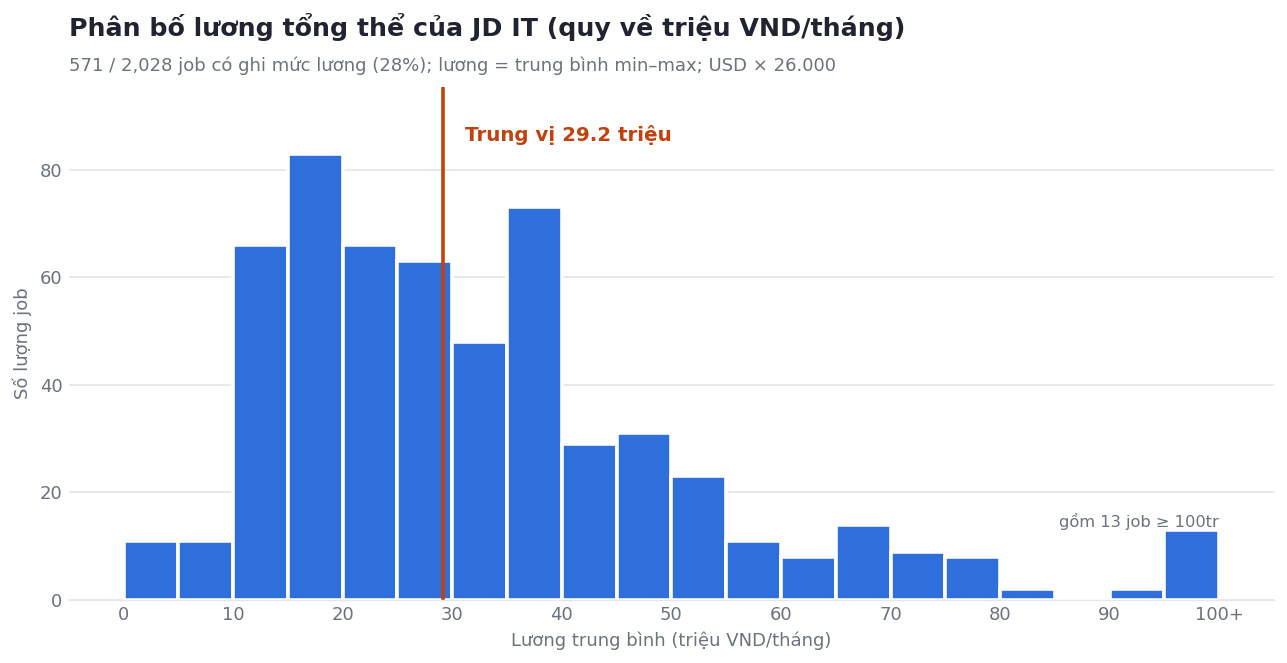

In [5]:
INK, MUTED, GRID, BAR, MARK = "#1f2430", "#6b7280", "#e5e7eb", "#2f6fdb", "#c2410c"

sal = df.loc[df["salary_avg_vnd"].notna(), "salary_avg_vnd"] / 1e6   # triệu VND / tháng
n_sal, n_all = len(sal), len(df)
med = sal.median()

bins = np.arange(0, 105, 5)                                          # mỗi cột = 5 triệu
clipped = sal.clip(upper=bins[-1] - 0.01)                            # gộp lương >= 100tr vào cột cuối
n_over = int((sal >= bins[-1]).sum())

fig, ax = plt.subplots(figsize=(10, 5.2), dpi=130)
counts, edges, _ = ax.hist(clipped, bins=bins, color=BAR, edgecolor="white", linewidth=2)

ax.axvline(med, color=MARK, linewidth=2)
ax.annotate(f"Trung vị {med:.1f} triệu", xy=(med, counts.max()), xytext=(med + 2, counts.max() * 1.02),
            color=MARK, fontsize=11, fontweight="bold", va="bottom")

ax.set_title("Phân bố lương tổng thể của JD IT (quy về triệu VND/tháng)", loc="left", fontsize=14,
             color=INK, fontweight="bold", pad=28)
ax.text(0, 1.03, f"{n_sal:,} / {n_all:,} job có ghi mức lương ({n_sal / n_all:.0%}); "
        f"lương = trung bình min–max; USD × 26.000", transform=ax.transAxes, fontsize=10, color=MUTED)
ax.set_xlabel("Lương trung bình (triệu VND/tháng)", color=MUTED)
ax.set_ylabel("Số lượng job", color=MUTED)
ax.set_xticks(np.arange(0, 105, 10))
ax.set_xticklabels([str(t) for t in range(0, 100, 10)] + ["100+"])
ax.set_ylim(0, counts.max() * 1.15)
ax.yaxis.grid(True, color=GRID, linewidth=1)
ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(colors=MUTED, length=0)
if n_over:
    ax.text(bins[-1], counts[-1], f"gồm {n_over} job ≥ 100tr", ha="right", va="bottom", fontsize=9, color=MUTED)
fig.tight_layout()
plt.show()

In [6]:
df.head(20)

,source,job_id,title,company_name,company_size,company_size_avg,salary_type,salary_min_vnd,salary_max_vnd,salary_avg_vnd,...,job_type_std,exp_min_years,exp_max_years,exp_avg_years,skills,n_skills,benefits,posted_date,expires_date,days_open
0,itviec,0848,Chuyên viên Vận hành ứng dụng,SHS | Chứng khoán Sài Gòn - Hà Nội,NaN,NaN,negotiable,NaN,NaN,NaN,...,Full-time,NaN,NaN,NaN,IT Support | Windows | Linux | AI | Oracle | SQL,6,NaN,2026-09-22,2026-10-27,35.0
1,itviec,5143,Technical Business Analyst – Digital Lending,Công Ty Cổ Phần Dịch Vụ Fincon Global,NaN,NaN,range,25000000.0,40000000.0,32500000.0,...,Full-time,NaN,NaN,NaN,Business Analysis | Repository pattern | AI | API,4,NaN,2026-10-09,2026-11-13,35.0
2,itviec,0906,"System Admin (Networking, Digital Transformation)",Công ty CP Halcom Việt Nam,NaN,NaN,negotiable,NaN,NaN,NaN,...,Full-time,NaN,NaN,NaN,System Admin | Cloud | Cybersecurity | Databas...,5,NaN,2026-10-10,2026-11-14,35.0
3,itviec,1920,Senior IT Business Analyst,Mcredit - Công ty Tài chính TNHH MB Shinsei,NaN,NaN,negotiable,NaN,NaN,NaN,...,Full-time,NaN,NaN,NaN,Business Analysis | API | Database | Machine L...,5,NaN,2026-10-14,2026-11-18,35.0
4,itviec,1643,"DevOps Engineer (Python, AWS, Linux)",Techcom Securities,NaN,NaN,negotiable,NaN,NaN,NaN,...,Full-time,NaN,NaN,NaN,DevOps | CI/CD | Docker | Azure | AWS | Python,6,NaN,2026-09-24,2026-10-29,35.0
5,itviec,5339,"2D Game VFX Artist (Cocos Creator, Photoshop, ...",Công Ty Cổ Phần Hermon Game Việt Nam,NaN,NaN,range,15000000.0,22000000.0,18500000.0,...,Full-time,NaN,NaN,NaN,Games | Spine | Design | Adobe Photoshop | Coc...,5,NaN,2026-10-24,2026-11-28,35.0
6,itviec,2706,"FinTech Frontend Dev (JavaScript, React)",New Wealth,NaN,NaN,range,39000000.0,78000000.0,58500000.0,...,Full-time,NaN,NaN,NaN,JavaScript | ReactJS | CSS,3,NaN,2026-10-19,2026-11-23,35.0
7,itviec,5035,AI-Native Fullstack Developer / Vibe Coding De...,MediaX,NaN,NaN,range,13000000.0,15574000.0,14287000.0,...,Full-time,NaN,NaN,NaN,AI | Docker | Database | NextJS | Python | Eng...,6,NaN,2026-09-22,2026-10-27,35.0
8,itviec,4224,"UI UX Designer (Figma, Design System, User flows)",CÔNG TY CỔ PHẦN THIẾT KẾ GURU,NaN,NaN,negotiable,NaN,NaN,NaN,...,Full-time,NaN,NaN,NaN,UI-UX | Adobe Photoshop | Prototyping | Design...,6,NaN,2026-09-19,2026-10-24,35.0
9,itviec,0141,"Software Developer (Fresher/Junior, Good English)",Netcompany,NaN,NaN,negotiable,NaN,NaN,NaN,...,Full-time,NaN,NaN,NaN,.NET | TypeScript | JavaScript | Java | C# | E...,7,NaN,2026-10-19,2026-11-23,35.0
